In [2]:
import numpy as np
import matplotlib.pyplot as plt
from profield.data import *
from profield.lpt2d import evolve_lpt2d
from nbodykit.cosmology import Cosmology

# Loading Simulation Data

The GADGET-4 simulations on the BNL SDCC cluster have the following structure:
- The main directory containing all relevant simulations is located at `/gpfs/mnt/gpfs02/astro/workarea/khong/gadget4/examples/pf`
- A single simulation and its snapshots are stored in each `output` directory
- $N=128$, $L=250$ Mpc/h, $z_{\rm ini} = 63$
- Some simulations have `snapshot_ics_000.hdf5` files which contain the initial conditions at $z=63$; All sims *except* full sims 50-99 have it (because sims 50-99 have initial conditions in `snapshot_000.hdf5`)

### Simulation types
- The **full** simulations `output_[0-99]` have same initial projected field (same $k_z=0$ seed) but all other modes unique
    - Sims 0-49 have 20 snapshots
    - Sims 50-99 have 12 snapshots
- The **flat** simulation `output_onlyPF` has the same fixed projected seed as the full sims, but all $k_z \neq 0$ modes are nulled (only 2D gravity, hence flat)
- The **bulk** simulation `output_noPF` has the $k_z=0$ mode nulled (evolution of bulk modes)  



To load simulations, you need to define `SimConfig(sim_dir, sim_inds, snap_inds)` objects, where 
- `sim_dir` is the directory name of simulations (NOT FULL PATH)
- `sim_inds` is the number of simulations (only applicable to full sims) as int, tuple of index range, or list of indices. If multiple indices are given, then it will find simulations with directory `sim_dir + '_{idx}'`
- `snap_inds` is the number of snapshots as int, tuple of index ranges, or list of indices. 
- `use_ics` set to True uses the `snapshot_ics_000.hdf5` file in a simulation

You can then create a `GadgetDataset` (which is a PyTorch Dataset class) and use `make_projected_fields` to load all projected density fields from simulations. The returned field array will have shape (N_sims, N_snapshots, 3, Ngrid, Ngrid) where the 3rd dim indicates the 3 spatial dimensions of projection (x, y, z).

In [2]:
sim_configs = dict(
    full = SimConfig('output', [80,81], [0, 11], use_ics=False),
    flat = SimConfig('output_onlyPF', 1, [0, 20], use_ics=True),
    bulk = SimConfig('output_zeroPF', 1, [0, 20], use_ics=True)
)

In [3]:
dataset = GadgetDataset(
    Ngrid=128,
    Lbox=250.0,
    root_dir='/gpfs/mnt/gpfs02/astro/workarea/khong/gadget4/examples/pf',
    sim_configs=sim_configs,
    resampler='tsc'
)

In [4]:
fields, zs = make_projected_fields(dataset)
# np.savez('projected_fields.npz', fields=fields, zs=zs)

Making projected fields from simulations...


 Simulation 0
 Simulation 1
 Simulation 2
 Simulation 3


Use the following sim_configs to load all 100 full sims + 1 flat sim + 1 bulk sim (**NOTE**: will take a long time to run, make sure to save fields after to load them faster)

You must indicate separate simulations for sims 0-49 and 50-99 because they have slightly different structure.

In [5]:
# # snapshot indices of 20-snapshot sims that match 12-snapshot sims
# match_inds = [0,1,2,4,5,6,8,10,12,15,18,20]

# sim_configs = dict(
#     full_0 = SimConfig('output', (0,50), match_inds),
#     full_1 = SimConfig('output', (50,100), list(range(12))),
#     flat =   SimConfig('output_onlyPF', 1, match_inds),
#     bulk =   SimConfig('output_zeroPF', 1, match_inds)
# )

# 2LPT-2D

In [6]:
# Setup cosmology (these are fiducial values of all simulations)
cosmo = Cosmology(h=0.678, Omega0_b=0.0482, Omega0_cdm=0.308, n_s=1.0)
cosmo = cosmo.match(0.9) # Match sigma8 value

In [7]:
# Get initial projected field of flat sim, defined above
field_init = fields[2,0,2]
Ngrid = 128
Lbox = 250.0
z = 0.0

In [8]:
field_lpt2d = evolve_lpt2d(cosmo, field_init, Ngrid, Lbox, z, lpt_order=1, resampler='tsc')

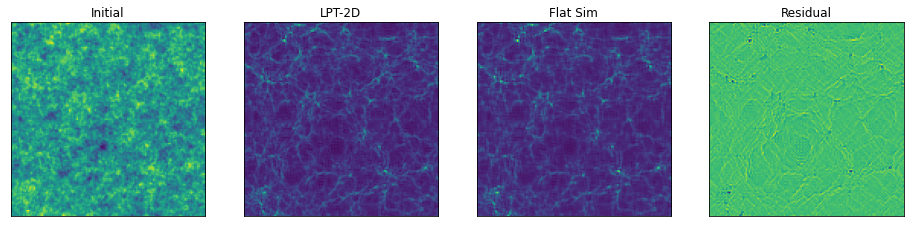

In [9]:
field_flat = fields[2,-1,2]
titles = ['Initial', 'LPT-2D', 'Flat Sim', 'Residual']
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'

fig, ax = plt.subplots(1, 4, figsize=(16,4))
ax[0].imshow(field_init)
im = ax[2].imshow(field_flat)
ax[1].imshow(field_lpt2d, clim=im.get_clim())
ax[3].imshow(field_lpt2d - field_flat)
for i in range(len(ax)):
    ax[i].set(xticks=[], yticks=[], title=titles[i])

/astro/u/khong/workarea/miniconda3/envs/bnl/lib/python3.6/site-packages/ipykernel_launcher.py:7: RuntimeWarning: invalid value encountered in true_divide
  import sys


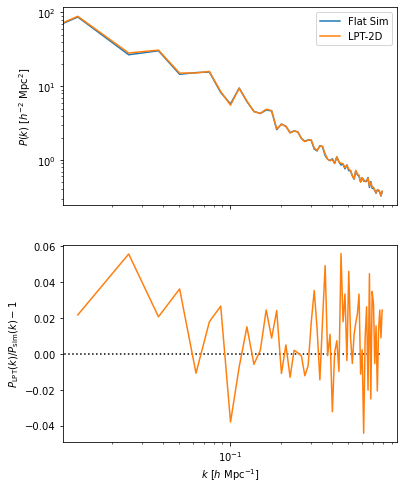

In [18]:
pk_flat, k = power_spectrum_2D(field_flat, field_flat, Lbox)
pk_lpt2d, k = power_spectrum_2D(field_lpt2d, field_lpt2d, Lbox)

fig, ax = plt.subplots(2, 1, figsize=(6,8), sharex=True)
ax[0].loglog(k, pk_flat, label='Flat Sim')
ax[0].loglog(k, pk_lpt2d, label='LPT-2D')
ax[1].plot(k, pk_lpt2d / pk_flat - 1, color='C1')
ax[0].set(ylabel=r'$P(k)\ [h^{-2}\ \mathrm{Mpc}^2]$')
ax[0].legend()
ax[1].set(xscale='log', xlabel=r'$k\ [h\ \mathrm{Mpc}^{-1}]$', ylabel=r'$P_{\rm LPT}(k) / P_{\rm sim}(k) - 1$')
ax[1].hlines(0, k.min(), k.max(), color='k', ls=':')

# LPT Suppression

In [7]:
# Setup cosmology (these are fiducial values of all simulations)
cosmo = Cosmology(h=0.678, Omega0_b=0.0482, Omega0_cdm=0.308, n_s=1.0)
cosmo = cosmo.match(0.9) # Match sigma8 value
N, L = 128, 250.0

In [4]:
data_full = np.load('data/output_fields_100sims_N128_allsnaps.npz')
data_flat = np.load('data/output_onlyPF_fields_100sims_N128_allsnaps.npz')

In [ ]:
fields = {}
fields['Full'] = data_full['fields'] / 128 # Old data; divide by 128 to scale correctly as projected mean (NOT SUM)
fields['Flat'] = data_flat['fields'] / 128
fields['Mean'] = np.mean(fields['Full'], axis=0)[None,:]
zs = data_full['redshifts']

In [8]:
Pks = {}
for j, (name, f) in enumerate(fields.items()):
    Pks_i = np.zeros((*f.shape[:3],f.shape[-1]//2))
    for s_i in range(f.shape[0]):
        for z_i in range(f.shape[1]):
            for d_i in range(f.shape[2]):
                f_i = f[s_i,z_i,d_i]
                Pks_i[s_i,z_i,d_i], k = power_spectrum_2D(f_i,f_i,L)
    Pks[name] = Pks_i

In [9]:
field_init = fields['Flat'][0,0,2]
fields['LPT-2D'] = np.zeros_like(fields['Flat'])
Pks['LPT-2D'] = np.zeros_like(Pks['Flat'])
for z_i, z in enumerate(zs):
    flpt2d = evolve_lpt2d(cosmo, field_init, N, L, z=z, lpt_order=1, resampler='tsc')
    fields['LPT-2D'][0,z_i,2] = flpt2d
    pklpt2d, _ = power_spectrum_2D(flpt2d, flpt2d, L)
    Pks['LPT-2D'][0,z_i,2] = pklpt2d


In [11]:
Pks['MxFlat'] = np.zeros_like(Pks['Flat'])
for z_i, z in enumerate(zs):
    pk_mxf, _ = power_spectrum_2D(fields['Flat'][0,z_i,2], fields['Mean'][0,z_i,2], L)
    Pks['MxFlat'][0,z_i,2] = pk_mxf / Pks['Flat'][0,z_i,2]

/home/khong/miniconda3/envs/bnl/lib/python3.6/site-packages/ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in true_divide
  after removing the cwd from sys.path.


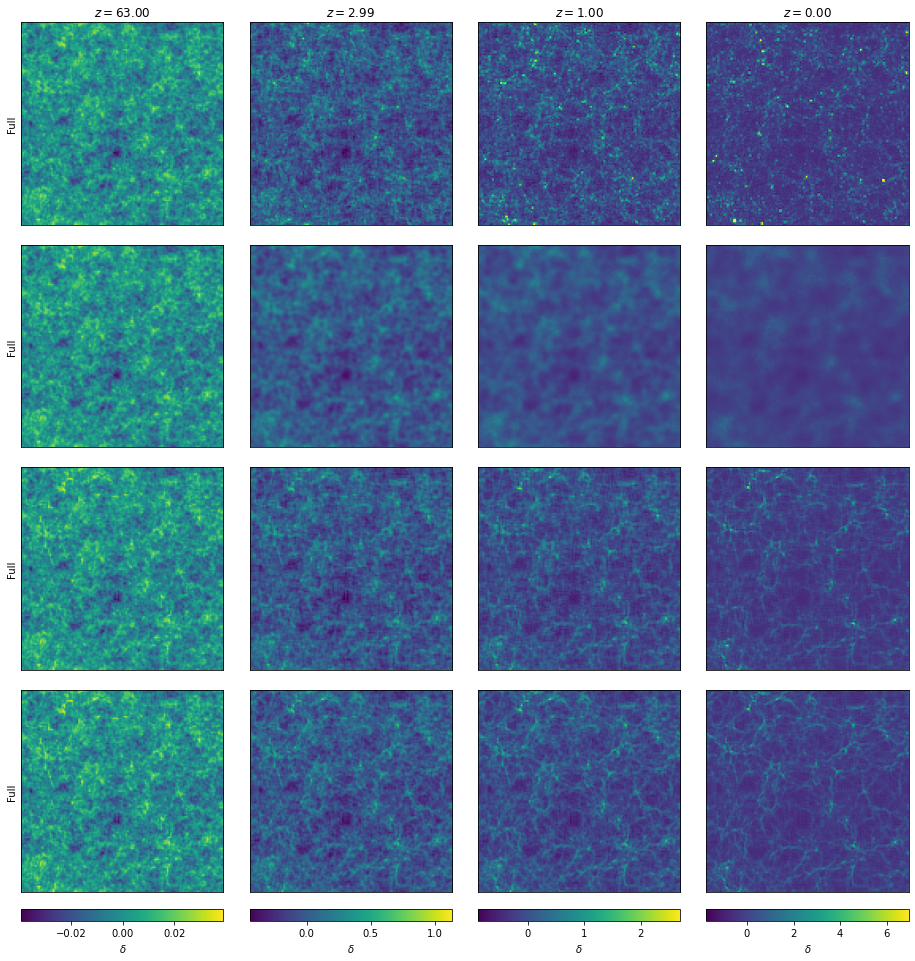

In [31]:
z_inds = [0, 4, 7, 11]
names = ['Full', 'Mean', 'Flat', 'LPT-2D']
clim_scales = [1, 0.9, 0.8, 0.6]

fig, ax = plt.subplots(4, 4, figsize=(16,16))
fig.patch.set_facecolor('white')
fig.subplots_adjust(wspace=0.1, hspace=0.1)
for j, z_i in enumerate(z_inds):
    clim = None
    for i, name in enumerate(names):
        im = ax[i,j].imshow(fields[name][0,z_i,2])
        if clim is None:
            clim = im.get_clim()
            clim = (clim[0], clim[1]*clim_scales[j])
        im.set_clim(clim)
        ax[i,j].set(xticks=[], yticks=[])
        if i == 0:
            ax[i,j].set(title=rf'$z={zs[z_i]:.2f}$')
        if j == 0:
            ax[i,j].set(ylabel=names[j])
    ax_pos = ax[0,j].get_position().get_points()
    cax = fig.add_axes([ax_pos[0,0], 0.1, ax_pos[1,0]-ax_pos[0,0], 0.01])
    cbar = fig.colorbar(im, cax=cax, orientation='horizontal')
    cbar.set_label(r'$\delta$')

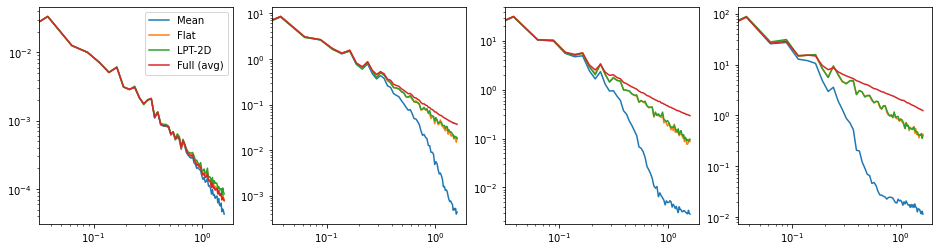

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(16,4))
for j, z_i in enumerate([0,4,7,11]):
    ax[j].loglog(k, Pks['Mean'][0,z_i,2], label='Mean')
    ax[j].loglog(k, Pks['Flat'][0,z_i,2], label='Flat')
    ax[j].loglog(k, Pks['LPT-2D'][0,z_i,2], label='LPT-2D')
    ax[j].loglog(k, Pks['Full'][:,z_i,2].mean(0), label='Full (avg)')
ax[0].legend()

In [20]:
import scipy
def gauss_fit(k, sigma2):
    return np.exp(-sigma2 * k**2 / 2)

Pks['MxFlat_fit'] = np.zeros_like(Pks['MxFlat'])
params = []
for z_i, z in enumerate(zs):
    popt, pcov = scipy.optimize.curve_fit(gauss_fit, k[1:], Pks['MxFlat'][0,z_i,2,1:])
    Pks['MxFlat_fit'][0,z_i,2] = gauss_fit(k, *popt)
    params.append(popt[0]) 
print(params)

[0.2555721131037088, 0.28308663565812564, 0.49421781719406316, 1.5039656609579728, 2.2173519223142732, 3.039573563299661, 4.990658011011449, 7.21251273452494, 9.508972699161506, 12.777469183917823, 15.57758370915576, 17.166054327412517]


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(12,4))

# `params[z_i]` is the *measured* effective suppression Sigma^2(z) obtained by
# fitting exp(-Sigma^2 k^2 / 2) to the measured ratio P_me/P_ee at redshift z.
# This is the quantity to quote as the measured suppression at that redshift, and
# it is compared directly against the theory prediction
#     Sigma^2(z) = Sigma^2(z=0) * D(z)^2 ,  Sigma^2(z=0) = 25.1 (Mpc/h)^2,
# which *decreases* towards high z (the field becomes linear). Do NOT divide the
# measured value by D(z)^2: that yields the z=0-equivalent, not Sigma^2(z).
# Note: the paper quotes the predicted values using the simulation's own growth
# factor (D(1)=0.609, D(3)=0.317 -> 9.3, 2.5); nbodykit's growth below differs by ~few %.
print(f"{'z':>6} {'D(z)':>7} {'measured Sigma^2':>17} {'predicted 25.1 D^2':>19}")
for j, z_i in enumerate([4,7,11]):
    ax[j].loglog(k, Pks['MxFlat'][0,z_i,2], color='k', label=r'$P_{me} / P_{ee}$')
    ax[j].loglog(k, Pks['MxFlat_fit'][0,z_i,2], color='tab:green', label='Best Fit')
    ax[j].set(ylim=(0.01, 1.3))
    growth_factor = cosmo.scale_independent_growth_factor(zs[z_i])
    sigma2_meas = params[z_i]                  # measured effective Sigma^2(z)
    sigma2_pred = 25.1 * growth_factor**2      # theory, scaled DOWN by D(z)^2
    print(f"{zs[z_i]:6.2f} {growth_factor:7.3f} {sigma2_meas:17.2f} {sigma2_pred:19.2f}")
    ax[j].plot(k, gauss_fit(k, 35.4 * growth_factor**2), color='r', ls=':', label=r'$\Sigma^2_Z$')
    ax[j].plot(k, gauss_fit(k, sigma2_pred), color='r', ls='--', label=r'$\Sigma^2$')
    ax[j].set(title=f'z = {zs[z_i]:.1f}', xlabel=r'$k\ \rm [h\ Mpc^{-1}]$')
ax[0].set(ylabel=r'$P_{me} / P_{ee}$')
ax[0].legend()
plt.show()


In [ ]:
# Suppression measured against the FULL nonlinear power spectrum (black line in the P(k) figure).
# In the Likelihood section the residual is tied to the full power P_ff, so the relevant quantity
# is the signal-power fraction S^2 = P_mm/P_ff = exp(-k^2 Sigma^2). Note the FULL k^2: this is a
# *power* ratio, whereas P_me/P_ee is a *cross*-spectrum and carries exp(-k^2 Sigma^2 / 2). Both
# recover the same Sigma^2 (the mean-field amplitude damping exp(-1/2 D^2 k^2 Sigma^2)).
# P_mf/P_ff (cross of the mean field with a single full realization) is a noisier estimate of the
# same thing -- since the mean field IS the average of the full fields, <P_mf> = P_mm exactly.
def gauss_fit_power(k, sigma2):
    return np.exp(-sigma2 * k**2)

Pks['Full_mean'] = Pks['Full'].mean(0)         # mean full auto-power (black line in P(k) figure)
i_rep = 88                                      # fiducial realization used in the Likelihood section
print(f"{'z':>6} {'D(z)':>6} {'pred 25.1 D^2':>13} {'meas Pme/Pee':>13} {'Pmm/Pff':>9} {'Pmf/Pff':>9}")
sigma2_full = {}
for z_i in [4, 7, 11]:
    z = zs[z_i]
    D = cosmo.scale_independent_growth_factor(z)
    pk_mm, _ = power_spectrum_2D(fields['Mean'][0,z_i,2], fields['Mean'][0,z_i,2], L)
    pk_mf, _ = power_spectrum_2D(fields['Mean'][0,z_i,2], fields['Full'][i_rep,z_i,2], L)
    pk_ff = Pks['Full_mean'][z_i,2]
    s_mm = scipy.optimize.curve_fit(gauss_fit_power, k[1:], (pk_mm/pk_ff)[1:])[0][0]
    s_mf = scipy.optimize.curve_fit(gauss_fit_power, k[1:], (pk_mf/pk_ff)[1:])[0][0]
    sigma2_full[z_i] = s_mm
    print(f"{z:6.2f} {D:6.3f} {25.1*D**2:13.2f} {params[z_i]:13.2f} {s_mm:9.2f} {s_mf:9.2f}")


In [ ]:
# Equivalent of the P_me/P_ee figure above, but for the full-power ratio P_mm/P_ff.
# Same plotting style; note the power convention exp(-k^2 Sigma^2) (full k^2, not k^2/2).
# Just the measured ratio vs the Gaussian best fit (no theory overlay).
fig, ax = plt.subplots(1, 3, figsize=(12,4))
for j, z_i in enumerate([4,7,11]):
    z = zs[z_i]
    pk_mm, _ = power_spectrum_2D(fields['Mean'][0,z_i,2], fields['Mean'][0,z_i,2], L)
    ratio = pk_mm / Pks['Full_mean'][z_i,2]
    popt, _ = scipy.optimize.curve_fit(gauss_fit_power, k[1:], ratio[1:])
    ax[j].loglog(k, ratio, color='k', label=r'$P_{mm}/P_{ff}$')
    ax[j].loglog(k, gauss_fit_power(k, *popt), color='tab:green', label='Best Fit')
    ax[j].set(ylim=(0.01, 1.3), title=f'z = {z:.1f}', xlabel=r'$k\ \rm [h\ Mpc^{-1}]$')
ax[0].set(ylabel=r'$P_{mm}/P_{ff}$')
ax[0].legend()
plt.show()
